In [19]:
import gc
import torch

# Clear Python garbage
gc.collect()

# Clear CUDA cache
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

print("GPU memory cleared.")

GPU memory cleared.


In [20]:
if torch.cuda.is_available():
    print(torch.cuda.memory_summary())
else:
    print("CUDA is not available.")

|===========================================================================|
|                  PyTorch CUDA memory summary, device ID 0                 |
|---------------------------------------------------------------------------|
|            CUDA OOMs: 0            |        cudaMalloc retries: 0         |
|===========================================================================|
|        Metric         | Cur Usage  | Peak Usage | Tot Alloc  | Tot Freed  |
|---------------------------------------------------------------------------|
| Allocated memory      |      0 B   |      0 B   |      0 B   |      0 B   |
|       from large pool |      0 B   |      0 B   |      0 B   |      0 B   |
|       from small pool |      0 B   |      0 B   |      0 B   |      0 B   |
|---------------------------------------------------------------------------|
| Active memory         |      0 B   |      0 B   |      0 B   |      0 B   |
|       from large pool |      0 B   |      0 B   |      0 B   |

In [3]:
import os
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from PIL import Image
from torch.utils.data import Dataset, DataLoader

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Dataset paths
DATA_ROOT = "/kaggle/input/datasets/faiznadeem39/milk10k"

GT_PATH = os.path.join(DATA_ROOT, "MILK10k_Training_GroundTruth.csv")
META_PATH = os.path.join(DATA_ROOT, "MILK10k_Training_Metadata.csv")

IMAGE_ROOT = os.path.join(
    DATA_ROOT,
    "MILK10k_Training_Input",
    "MILK10k_Training_Input"
)

print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not available")

print("\nGround Truth exists:", os.path.exists(GT_PATH))
print("Metadata exists:", os.path.exists(META_PATH))
print("Image directory exists:", os.path.exists(IMAGE_ROOT))

Device: cuda
GPU: Tesla T4

Ground Truth exists: True
Metadata exists: True
Image directory exists: True


In [24]:
# Load CSV files
gt = pd.read_csv(GT_PATH)
metadata = pd.read_csv(META_PATH)

# Original class columns
class_names = [
    "AKIEC", "BCC", "BEN_OTH", "BKL", "DF",
    "INF", "MAL_OTH", "MEL", "NV", "SCCKA", "VASC"
]

# Convert one-hot labels into class names
gt["label"] = gt[class_names].idxmax(axis=1)

print("Ground Truth shape:", gt.shape)
print("Metadata shape:", metadata.shape)

print("\nOriginal class distribution:")
print(gt["label"].value_counts().reindex(class_names))

print("\nGround Truth columns:")
print(gt.columns.tolist())

print("\nMetadata columns:")
print(metadata.columns.tolist())

Ground Truth shape: (5240, 13)
Metadata shape: (10480, 17)

Original class distribution:
label
AKIEC       303
BCC        2522
BEN_OTH      44
BKL         544
DF           52
INF          50
MAL_OTH       9
MEL         450
NV          746
SCCKA       473
VASC         47
Name: count, dtype: int64

Ground Truth columns:
['lesion_id', 'AKIEC', 'BCC', 'BEN_OTH', 'BKL', 'DF', 'INF', 'MAL_OTH', 'MEL', 'NV', 'SCCKA', 'VASC', 'label']

Metadata columns:
['lesion_id', 'image_type', 'isic_id', 'attribution', 'copyright_license', 'image_manipulation', 'age_approx', 'sex', 'skin_tone_class', 'site', 'MONET_ulceration_crust', 'MONET_hair', 'MONET_vasculature_vessels', 'MONET_erythema', 'MONET_pigmented', 'MONET_gel_water_drop_fluid_dermoscopy_liquid', 'MONET_skin_markings_pen_ink_purple_pen']


In [25]:
# Classes having at least 100 lesions
class_names = ["BCC", "NV", "BKL", "SCCKA", "MEL", "AKIEC"]

# Filter ground truth
gt_filtered = gt[gt["label"].isin(class_names)].copy()

# Create clinical image dataframe
clinical = metadata[
    metadata["image_type"] == "clinical: close-up"
][["lesion_id", "isic_id"]].rename(
    columns={"isic_id": "clinical_id"}
)

# Create dermoscopic image dataframe
dermoscopic = metadata[
    metadata["image_type"] == "dermoscopic"
][["lesion_id", "isic_id"]].rename(
    columns={"isic_id": "dermoscopic_id"}
)

# Pair both modalities using lesion_id
paired = clinical.merge(
    dermoscopic,
    on="lesion_id",
    validate="one_to_one"
)

# Attach filtered labels
paired = paired.merge(
    gt_filtered[["lesion_id", "label"]],
    on="lesion_id",
    validate="one_to_one"
)

# Reindex classes
label_to_idx = {label: idx for idx, label in enumerate(class_names)}
paired["label_idx"] = paired["label"].map(label_to_idx)

print("Paired dataset:", paired.shape)

print("\nClass mapping:")
print(label_to_idx)

print("\nClass distribution:")
print(paired["label"].value_counts().reindex(class_names))

print("\nMissing labels:", paired["label_idx"].isna().sum())

Paired dataset: (5038, 5)

Class mapping:
{'BCC': 0, 'NV': 1, 'BKL': 2, 'SCCKA': 3, 'MEL': 4, 'AKIEC': 5}

Class distribution:
label
BCC      2522
NV        746
BKL       544
SCCKA     473
MEL       450
AKIEC     303
Name: count, dtype: int64

Missing labels: 0


In [26]:
# Create image paths
paired["clinical_path"] = paired.apply(
    lambda row: os.path.join(
        IMAGE_ROOT,
        row["lesion_id"],
        row["clinical_id"] + ".jpg"
    ),
    axis=1
)

paired["dermoscopic_path"] = paired.apply(
    lambda row: os.path.join(
        IMAGE_ROOT,
        row["lesion_id"],
        row["dermoscopic_id"] + ".jpg"
    ),
    axis=1
)

# Verify paths
missing_clinical = (~paired["clinical_path"].map(os.path.exists)).sum()
missing_dermoscopic = (~paired["dermoscopic_path"].map(os.path.exists)).sum()

print("Missing clinical images:", missing_clinical)
print("Missing dermoscopic images:", missing_dermoscopic)

print("\nSample paired record:")
print(paired.iloc[0][[
    "lesion_id",
    "clinical_path",
    "dermoscopic_path",
    "label",
    "label_idx"
]])

assert missing_clinical == 0
assert missing_dermoscopic == 0

print("\nAll image paths verified successfully.")

Missing clinical images: 0
Missing dermoscopic images: 0

Sample paired record:
lesion_id                                                  IL_0000652
clinical_path       /kaggle/input/datasets/faiznadeem39/milk10k/MI...
dermoscopic_path    /kaggle/input/datasets/faiznadeem39/milk10k/MI...
label                                                             BCC
label_idx                                                           0
Name: 0, dtype: object

All image paths verified successfully.


In [27]:
# First split: 80% training, 20% temporary
train_df, temp_df = train_test_split(
    paired,
    test_size=0.20,
    random_state=SEED,
    stratify=paired["label_idx"]
)

# Second split: 10% validation, 10% testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label_idx"]
)

# Reset indices
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# Display split sizes
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

print("\nClass distribution per split:")

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name}:")
    print(df["label"].value_counts().reindex(class_names))

# Verify lesion-level separation
train_ids = set(train_df["lesion_id"])
val_ids = set(val_df["lesion_id"])
test_ids = set(test_df["lesion_id"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

assert len(train_df) + len(val_df) + len(test_df) == len(paired)

print("\nLesion overlap: None")
print("Total samples:", len(train_df) + len(val_df) + len(test_df))

Training: 4030
Validation: 504
Testing: 504

Class distribution per split:

Train:
label
BCC      2018
NV        597
BKL       435
SCCKA     378
MEL       360
AKIEC     242
Name: count, dtype: int64

Validation:
label
BCC      252
NV        74
BKL       55
SCCKA     47
MEL       45
AKIEC     31
Name: count, dtype: int64

Test:
label
BCC      252
NV        75
BKL       54
SCCKA     48
MEL       45
AKIEC     30
Name: count, dtype: int64

Lesion overlap: None
Total samples: 5038


In [29]:
# Calculate training class counts
train_counts = (
    train_df["label_idx"]
    .value_counts()
    .sort_index()
)

# Inverse-frequency weights
raw_weights = 1.0 / train_counts.to_numpy(dtype=np.float64)

# Normalize weights so their sum equals 1
normalized_weights = raw_weights / raw_weights.sum()

# Convert to PyTorch tensor
class_weights = torch.tensor(
    normalized_weights,
    dtype=torch.float32,
    device=DEVICE
)

# Display results
weight_df = pd.DataFrame({
    "Class": class_names,
    "Training Samples": train_counts.to_numpy(),
    "Normalized Weight": normalized_weights
})

print(weight_df.to_string(index=False))

print("\nWeight sum:", class_weights.sum().item())

assert np.isclose(class_weights.sum().item(), 1.0, atol=1e-6)

Class  Training Samples  Normalized Weight
  BCC              2018           0.035333
   NV               597           0.119433
  BKL               435           0.163912
SCCKA               378           0.188628
  MEL               360           0.198060
AKIEC               242           0.294634

Weight sum: 1.0


In [37]:
import random
import matplotlib.pyplot as plt

from torchvision import transforms
from torchvision.transforms import functional as TF


# 1. Paired Training Augmentation
class PairedTrainTransform:

    def __init__(self, size=224):
        self.size = size

    def __call__(self, clinical, dermoscopic):

        # Same horizontal flip
        if random.random() < 0.5:
            clinical = TF.hflip(clinical)
            dermoscopic = TF.hflip(dermoscopic)

        # Same rotation angle
        angle = random.uniform(-15, 15)

        clinical = TF.rotate(clinical, angle)
        dermoscopic = TF.rotate(dermoscopic, angle)

        # Same resizing
        clinical = TF.resize(clinical, (self.size, self.size))
        dermoscopic = TF.resize(dermoscopic, (self.size, self.size))

        # Convert to tensors
        clinical = TF.to_tensor(clinical)
        dermoscopic = TF.to_tensor(dermoscopic)

        return clinical, dermoscopic


# 2. Evaluation Transform (No Random Augmentation)
class PairedTrainTransform:

    def __init__(self, size=224):
        self.size = size

    def __call__(self, clinical, dermoscopic):

        # Synchronized horizontal flip
        if random.random() < 0.5:
            clinical = TF.hflip(clinical)
            dermoscopic = TF.hflip(dermoscopic)

        # Resize both images
        clinical = TF.resize(clinical, (self.size, self.size))
        dermoscopic = TF.resize(dermoscopic, (self.size, self.size))

        # Convert to tensors
        clinical = TF.to_tensor(clinical)
        dermoscopic = TF.to_tensor(dermoscopic)

        return clinical, dermoscopic


train_transform = PairedTrainTransform(size=224)
eval_transform = PairedEvalTransform(size=224)

print("Updated paired augmentation initialized successfully.")


# 4. Visualization function
def visualize_augmentation(clinical_image, dermoscopic_image):

    # Apply augmentation
    aug_clinical, aug_dermoscopic = train_transform(
        clinical_image.copy(),
        dermoscopic_image.copy()
    )

    # Convert tensors to numpy for plotting
    original_clinical = TF.to_tensor(
        TF.resize(clinical_image, (224, 224))
    ).permute(1, 2, 0).numpy()

    original_dermoscopic = TF.to_tensor(
        TF.resize(dermoscopic_image, (224, 224))
    ).permute(1, 2, 0).numpy()

    aug_clinical = aug_clinical.permute(1, 2, 0).numpy()
    aug_dermoscopic = aug_dermoscopic.permute(1, 2, 0).numpy()

    # Display comparison
    fig, axes = plt.subplots(2, 2, figsize=(10, 10))

    axes[0, 0].imshow(original_clinical)
    axes[0, 0].set_title("Original Clinical")

    axes[0, 1].imshow(aug_clinical)
    axes[0, 1].set_title("Augmented Clinical")

    axes[1, 0].imshow(original_dermoscopic)
    axes[1, 0].set_title("Original Dermoscopic")

    axes[1, 1].imshow(aug_dermoscopic)
    axes[1, 1].set_title("Augmented Dermoscopic")

    for ax in axes.flat:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


print("Paired augmentation initialized successfully.")

Updated paired augmentation initialized successfully.
Paired augmentation initialized successfully.


In [38]:
class MILK10kDataset(Dataset):

    def __init__(self, dataframe, image_root, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_root = image_root
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        lesion_folder = row["lesion_id"]

        clinical_path = os.path.join(
            self.image_root,
            lesion_folder,
            row["clinical_id"] + ".jpg"
        )

        dermoscopic_path = os.path.join(
            self.image_root,
            lesion_folder,
            row["dermoscopic_id"] + ".jpg"
        )

        clinical_image = Image.open(clinical_path).convert("RGB")
        dermoscopic_image = Image.open(dermoscopic_path).convert("RGB")

        if self.transform:
            clinical_image, dermoscopic_image = self.transform(
                clinical_image, dermoscopic_image
            )

        label = int(row["label_idx"])

        return clinical_image, dermoscopic_image, label

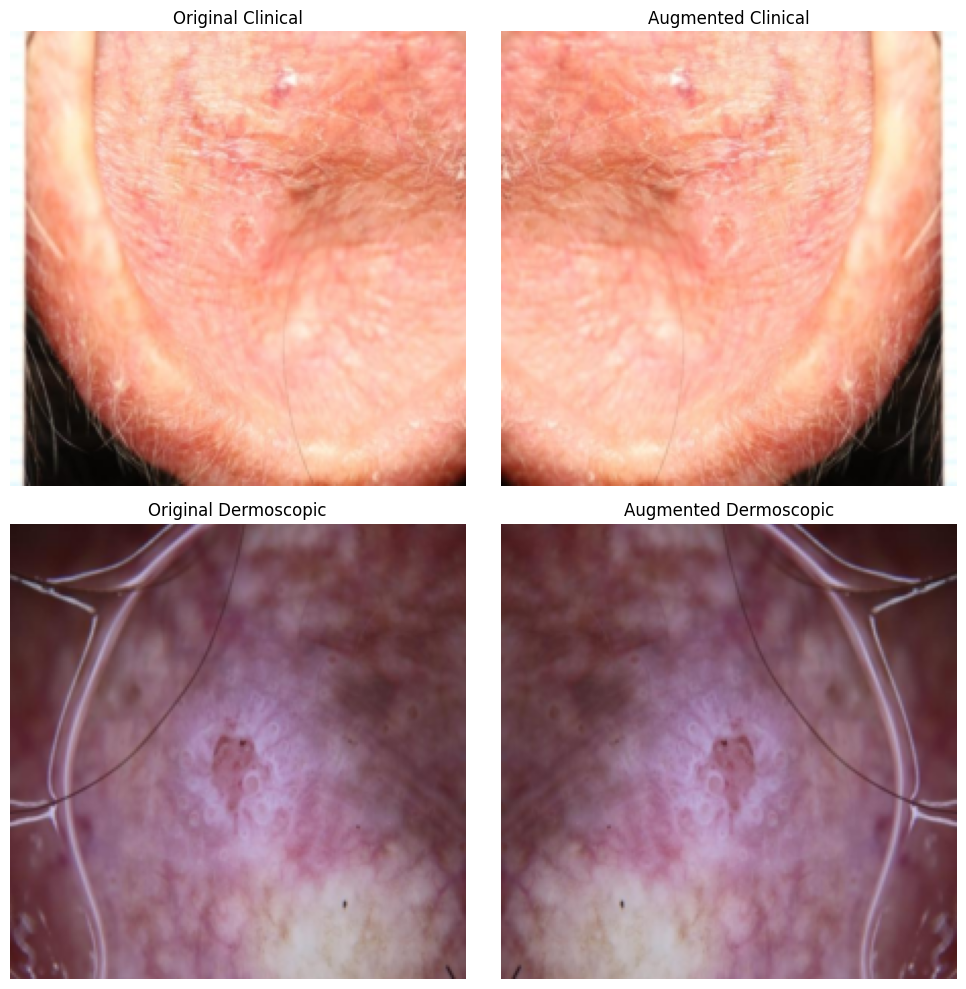

Class: SCCKA
Lesion ID: IL_6217582
Clinical image: /kaggle/input/datasets/faiznadeem39/milk10k/MILK10k_Training_Input/MILK10k_Training_Input/IL_6217582/ISIC_0194116.jpg
Dermoscopic image: /kaggle/input/datasets/faiznadeem39/milk10k/MILK10k_Training_Input/MILK10k_Training_Input/IL_6217582/ISIC_1720538.jpg


In [39]:
sample_idx = 0
row = train_df.iloc[sample_idx]

clinical_path = os.path.join(
    IMAGE_ROOT,
    row["lesion_id"],
    row["clinical_id"] + ".jpg"
)

dermoscopic_path = os.path.join(
    IMAGE_ROOT,
    row["lesion_id"],
    row["dermoscopic_id"] + ".jpg"
)

clinical_original = Image.open(clinical_path).convert("RGB")
dermoscopic_original = Image.open(dermoscopic_path).convert("RGB")

visualize_augmentation(
    clinical_original,
    dermoscopic_original
)

print("Class:", row["label"])
print("Lesion ID:", row["lesion_id"])
print("Clinical image:", clinical_path)
print("Dermoscopic image:", dermoscopic_path)

In [40]:
# Create dataset objects

train_dataset = MILK10kDataset(
    dataframe=train_df,
    image_root=IMAGE_ROOT,
    transform=train_transform
)

val_dataset = MILK10kDataset(
    dataframe=val_df,
    image_root=IMAGE_ROOT,
    transform=eval_transform
)

test_dataset = MILK10kDataset(
    dataframe=test_df,
    image_root=IMAGE_ROOT,
    transform=eval_transform
)

# Verify dataset sizes
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

# Inspect one training sample
clinical, dermoscopic, label = train_dataset[0]

print("\nSample verification:")
print("Clinical shape:", clinical.shape)
print("Dermoscopic shape:", dermoscopic.shape)
print("Label:", label)
print("Class:", class_names[label])

Training samples: 4030
Validation samples: 504
Testing samples: 504

Sample verification:
Clinical shape: torch.Size([3, 224, 224])
Dermoscopic shape: torch.Size([3, 224, 224])
Label: 3
Class: SCCKA


In [41]:
from torch.utils.data import DataLoader

BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

# Verify one batch
clinical, dermoscopic, labels = next(iter(train_loader))

print("\nBatch verification:")
print("Clinical:", clinical.shape)
print("Dermoscopic:", dermoscopic.shape)
print("Labels:", labels.shape)

Train batches: 504
Validation batches: 63
Test batches: 63

Batch verification:
Clinical: torch.Size([8, 3, 224, 224])
Dermoscopic: torch.Size([8, 3, 224, 224])
Labels: torch.Size([8])


In [42]:
import torch
import torch.nn as nn
from spikingjelly.activation_based import neuron, surrogate, functional


# 1. Squeeze-and-Excitation Block
class SEBlock(nn.Module):
    def __init__(self, channels, reduction=4):
        super().__init__()

        mid = max(channels // reduction, 8)

        self.squeeze = nn.AdaptiveAvgPool2d(1)

        self.excitation = nn.Sequential(
            nn.Linear(channels, mid, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(mid, channels, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _, _ = x.shape

        weights = self.squeeze(x).view(b, c)
        weights = self.excitation(weights).view(b, c, 1, 1)

        return x * weights


# 2. Depthwise Separable Convolution
class DepthwiseSeparableConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()

        self.depthwise = nn.Conv2d(
            in_ch, in_ch,
            kernel_size=3,
            padding=1,
            groups=in_ch,
            bias=False
        )

        self.bn_dw = nn.BatchNorm2d(in_ch)

        self.pointwise = nn.Conv2d(
            in_ch, out_ch,
            kernel_size=1,
            bias=False
        )

        self.bn_pw = nn.BatchNorm2d(out_ch)

    def forward(self, x):
        x = self.bn_dw(self.depthwise(x))
        x = self.bn_pw(self.pointwise(x))

        return x


# 3. Spiking Block
class SpikeBlock(nn.Module):
    def __init__(self, in_ch, out_ch, tau=2.0):
        super().__init__()

        self.conv = DepthwiseSeparableConv(in_ch, out_ch)

        self.se = SEBlock(out_ch)

        self.lif = neuron.LIFNode(
            tau=tau,
            v_threshold=1.0,
            surrogate_function=surrogate.ATan(alpha=2.0),
            step_mode='s'
        )

        self.pool = nn.MaxPool2d(2, 2)

    def forward(self, x):
        x = self.conv(x)
        x = self.se(x)
        x = self.lif(x)
        x = self.pool(x)

        return x


# 4. NeurALLNet Feature Extractor
class NeurALLFeatureExtractor(nn.Module):
    def __init__(self):
        super().__init__()

        tau = 2.0

        self.stem = nn.Sequential(
            nn.Conv2d(
                3, 48,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(48),

            neuron.LIFNode(
                tau=tau,
                v_threshold=1.0,
                surrogate_function=surrogate.ATan(alpha=2.0),
                step_mode='s'
            ),

            nn.MaxPool2d(2, 2)
        )

        self.block1 = SpikeBlock(48, 96, tau)
        self.block2 = SpikeBlock(96, 192, tau)
        self.block3 = SpikeBlock(192, 384, tau)

        self.refine = nn.Sequential(
            nn.Conv2d(
                384, 384,
                kernel_size=3,
                padding=1,
                groups=384,
                bias=False
            ),
            nn.BatchNorm2d(384),

            nn.Conv2d(
                384, 256,
                kernel_size=1,
                bias=False
            ),
            nn.BatchNorm2d(256),

            neuron.LIFNode(
                tau=tau,
                v_threshold=1.0,
                surrogate_function=surrogate.ATan(alpha=2.0),
                step_mode='s'
            )
        )

        self.gap = nn.AdaptiveAvgPool2d(1)

    def forward(self, x):
        x = self.stem(x)
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.refine(x)
        x = self.gap(x).flatten(1)

        return x


# 5. Dual-Branch NeurALLNet
class DualBranchNeurALLNet(nn.Module):
    def __init__(self, num_classes=6, time_steps=4):
        super().__init__()

        self.T = time_steps

        # Clinical branch
        self.clinical_branch = NeurALLFeatureExtractor()

        # Dermoscopic branch
        self.dermoscopic_branch = NeurALLFeatureExtractor()

        # Feature fusion + classifier
        self.classifier = nn.Sequential(
            nn.Linear(512, 128, bias=False),
            nn.BatchNorm1d(128),

            neuron.LIFNode(
                tau=2.0,
                v_threshold=1.0,
                surrogate_function=surrogate.ATan(alpha=2.0),
                step_mode='s'
            ),

            nn.Dropout(0.3),

            nn.Linear(128, num_classes, bias=False)
        )

    def forward(self, clinical, dermoscopic):

        output_sum = None

        for t in range(self.T):

            functional.reset_net(self)

            clinical_features = self.clinical_branch(clinical)

            dermoscopic_features = self.dermoscopic_branch(
                dermoscopic
            )

            fused_features = torch.cat(
                (clinical_features, dermoscopic_features),
                dim=1
            )

            output = self.classifier(fused_features)

            if output_sum is None:
                output_sum = output
            else:
                output_sum = output_sum + output

        return output_sum / self.T


print("All architecture classes defined successfully.")

All architecture classes defined successfully.


In [43]:
def forward(self, clinical, dermoscopic):

    output_sum = None

    for t in range(self.T):

        clinical_features = self.clinical_branch(clinical)

        dermoscopic_features = self.dermoscopic_branch(
            dermoscopic
        )

        fused_features = torch.cat(
            (clinical_features, dermoscopic_features),
            dim=1
        )

        output = self.classifier(fused_features)

        if output_sum is None:
            output_sum = output
        else:
            output_sum = output_sum + output

    return output_sum / self.T

In [45]:
# Device configuration
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Initialize model
model = DualBranchNeurALLNet(
    num_classes=len(class_names),
    time_steps=4
).to(device)

# Count parameters
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)
print("Number of classes:", len(class_names))
print("Time steps:", model.T)

print("\nTotal parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

Number of classes: 6
Time steps: 4

Total parameters: 672,576
Trainable parameters: 672,576


In [46]:
model.eval()

clinical, dermoscopic, labels = next(iter(train_loader))

clinical = clinical.to(device)
dermoscopic = dermoscopic.to(device)

with torch.no_grad():
    outputs = model(clinical, dermoscopic)

functional.reset_net(model)

print("Clinical input:", clinical.shape)
print("Dermoscopic input:", dermoscopic.shape)
print("Model output:", outputs.shape)
print("Labels:", labels.shape)

Clinical input: torch.Size([8, 3, 224, 224])
Dermoscopic input: torch.Size([8, 3, 224, 224])
Model output: torch.Size([8, 6])
Labels: torch.Size([8])


In [47]:
import torch.nn as nn

# Weighted loss
class_weights = class_weights.to(device)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# Optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)

# Learning rate scheduler
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=lambda epoch: 10 ** (-epoch / 20)
)

# Training configuration
EPOCHS = 50
PATIENCE = 10

print("Loss Function:", criterion)
print("Optimizer:", optimizer)
print("Initial Learning Rate:", optimizer.param_groups[0]["lr"])
print("Epochs:", EPOCHS)
print("Early Stopping Patience:", PATIENCE)

Loss Function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    initial_lr: 0.001
    lr: 0.001
    maximize: False
    weight_decay: 0
)
Initial Learning Rate: 0.001
Epochs: 50
Early Stopping Patience: 10


In [48]:
import os
import numpy as np
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score

# Checkpoint path
CHECKPOINT_PATH = "/kaggle/working/neurALLnet_v03_best.pth"

best_val_f1 = -1.0
patience_counter = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_f1": [],
    "val_f1": [],
    "train_acc": [],
    "val_acc": []
}

for epoch in range(EPOCHS):

    # ---------------- TRAINING ----------------
    model.train()
    functional.reset_net(model)

    train_loss = 0.0
    train_preds = []
    train_labels = []

    train_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Train]")

    for clinical, dermoscopic, labels in train_bar:

        clinical = clinical.to(device)
        dermoscopic = dermoscopic.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(clinical, dermoscopic)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        train_preds.extend(predictions.detach().cpu().numpy())
        train_labels.extend(labels.detach().cpu().numpy())

        functional.reset_net(model)

        train_bar.set_postfix(loss=f"{loss.item():.4f}")

    train_loss /= len(train_loader.dataset)

    train_acc = accuracy_score(train_labels, train_preds)

    train_f1 = f1_score(
        train_labels,
        train_preds,
        labels=list(range(len(class_names))),
        average="macro",
        zero_division=0
    )

    # ---------------- VALIDATION ----------------
    model.eval()
    functional.reset_net(model)

    val_loss = 0.0
    val_preds = []
    val_labels = []

    with torch.no_grad():

        val_bar = tqdm(
            val_loader,
            desc=f"Epoch {epoch+1}/{EPOCHS} [Validation]"
        )

        for clinical, dermoscopic, labels in val_bar:

            clinical = clinical.to(device)
            dermoscopic = dermoscopic.to(device)
            labels = labels.to(device)

            outputs = model(clinical, dermoscopic)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            val_preds.extend(predictions.cpu().numpy())
            val_labels.extend(labels.cpu().numpy())

            functional.reset_net(model)

    val_loss /= len(val_loader.dataset)

    val_acc = accuracy_score(val_labels, val_preds)

    val_f1 = f1_score(
        val_labels,
        val_preds,
        labels=list(range(len(class_names))),
        average="macro",
        zero_division=0
    )

    # ---------------- SCHEDULER ----------------
    scheduler.step()

    # Store metrics
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_f1"].append(train_f1)
    history["val_f1"].append(val_f1)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    current_lr = optimizer.param_groups[0]["lr"]

    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | Train Macro F1: {train_f1:.4f}")
    print(f"Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.4f} | Val Macro F1:   {val_f1:.4f}")
    print(f"Learning Rate: {current_lr:.7f}")

    # ---------------- BEST CHECKPOINT ----------------
    if val_f1 > best_val_f1:

        best_val_f1 = val_f1
        patience_counter = 0

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_f1": best_val_f1,
            "class_names": class_names,
            "history": history
        }, CHECKPOINT_PATH)

        print(f"Best checkpoint saved! Macro F1: {best_val_f1:.4f}")

    else:
        patience_counter += 1
        print(f"No improvement: {patience_counter}/{PATIENCE}")

 # ---------------- EARLY STOPPING ----------------
    if patience_counter >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

print("\nTraining completed.")
print(f"Best Validation Macro F1: {best_val_f1:.4f}")
print(f"Checkpoint: {CHECKPOINT_PATH}")

Epoch 1/50 [Train]:   0%|          | 0/504 [00:00<?, ?it/s]

Epoch 1/50 [Validation]:   0%|          | 0/63 [00:00<?, ?it/s]


Epoch 1/50
Train Loss: 1.7366 | Train Acc: 0.4700 | Train Macro F1: 0.2208
Val Loss:   1.6718 | Val Acc:   0.5020 | Val Macro F1:   0.2788
Learning Rate: 0.0008913
Best checkpoint saved! Macro F1: 0.2788


Epoch 2/50 [Train]:   0%|          | 0/504 [00:00<?, ?it/s]

Epoch 2/50 [Validation]:   0%|          | 0/63 [00:00<?, ?it/s]


Epoch 2/50
Train Loss: 1.6219 | Train Acc: 0.4769 | Train Macro F1: 0.2876
Val Loss:   1.6627 | Val Acc:   0.5000 | Val Macro F1:   0.3099
Learning Rate: 0.0007943
Best checkpoint saved! Macro F1: 0.3099


... (137 outputs left out)


Epoch 47/50
Train Loss: 1.2518 | Train Acc: 0.5476 | Train Macro F1: 0.4408
Val Loss:   1.4449 | Val Acc:   0.4127 | Val Macro F1:   0.3707
Learning Rate: 0.0000045
No improvement: 9/10


Epoch 48/50 [Train]:   0%|          | 0/504 [00:00<?, ?it/s]

Epoch 48/50 [Validation]:   0%|          | 0/63 [00:00<?, ?it/s]


Epoch 48/50
Train Loss: 1.2552 | Train Acc: 0.5464 | Train Macro F1: 0.4361
Val Loss:   1.3872 | Val Acc:   0.4683 | Val Macro F1:   0.3834
Learning Rate: 0.0000040
No improvement: 10/10

Early stopping triggered.

Training completed.
Best Validation Macro F1: 0.4491
Checkpoint: /kaggle/working/neurALLnet_v03_best.pth


In [49]:
# Load the best validation checkpoint
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

functional.reset_net(model)

print("Best checkpoint loaded successfully!")
print("Best Epoch:", checkpoint["epoch"])
print("Best Validation Macro F1:", checkpoint["best_val_f1"])

Best checkpoint loaded successfully!
Best Epoch: 38
Best Validation Macro F1: 0.4490700006785903


Final Test Evaluation:   0%|          | 0/63 [00:00<?, ?it/s]


========== FINAL TEST RESULTS ==========
Test Loss:       1.3367
Test Accuracy:   0.5000
Test Precision:  0.3918
Test Recall:     0.4468
Test Macro F1:   0.4034
Test Weighted F1:0.5158

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

         BCC       0.79      0.54      0.64       252
          NV       0.57      0.69      0.62        75
         BKL       0.16      0.13      0.14        54
       SCCKA       0.35      0.62      0.45        48
         MEL       0.31      0.36      0.33        45
       AKIEC       0.17      0.33      0.23        30

    accuracy                           0.50       504
   macro avg       0.39      0.45      0.40       504
weighted avg       0.57      0.50      0.52       504



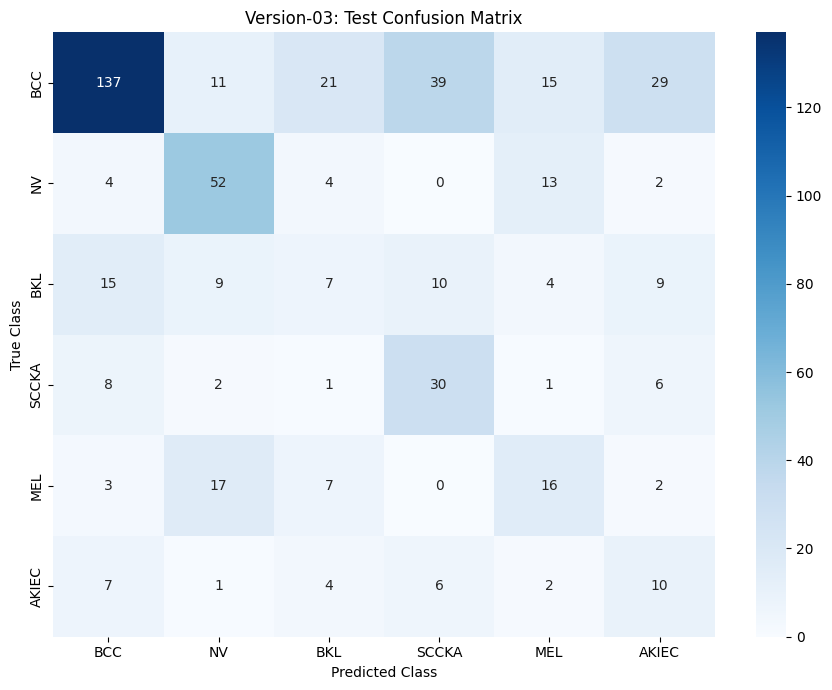

In [51]:

import seaborn as sns
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)


model.eval()
functional.reset_net(model)

test_loss = 0.0
test_preds = []
test_labels = []

with torch.no_grad():

    for clinical, dermoscopic, labels in tqdm(test_loader, desc="Final Test Evaluation"):

        clinical = clinical.to(device)
        dermoscopic = dermoscopic.to(device)
        labels = labels.to(device)

        outputs = model(clinical, dermoscopic)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        test_preds.extend(predictions.cpu().numpy())
        test_labels.extend(labels.cpu().numpy())

        functional.reset_net(model)

test_loss /= len(test_loader.dataset)

test_acc = accuracy_score(test_labels, test_preds)

test_precision = precision_score(
    test_labels, test_preds,
    average="macro",
    zero_division=0
)

test_recall = recall_score(
    test_labels, test_preds,
    average="macro",
    zero_division=0
)

test_f1 = f1_score(
    test_labels, test_preds,
    labels=list(range(len(class_names))),
    average="macro",
    zero_division=0
)

test_weighted_f1 = f1_score(
    test_labels, test_preds,
    average="weighted",
    zero_division=0
)

print("\n========== FINAL TEST RESULTS ==========")
print(f"Test Loss:       {test_loss:.4f}")
print(f"Test Accuracy:   {test_acc:.4f}")
print(f"Test Precision:  {test_precision:.4f}")
print(f"Test Recall:     {test_recall:.4f}")
print(f"Test Macro F1:   {test_f1:.4f}")
print(f"Test Weighted F1:{test_weighted_f1:.4f}")

print("\n========== CLASSIFICATION REPORT ==========")

print(classification_report(
    test_labels,
    test_preds,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

# Confusion Matrix
cm = confusion_matrix(
    test_labels,
    test_preds,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Version-03: Test Confusion Matrix")
plt.tight_layout()
plt.show()